<a href="https://colab.research.google.com/github/Tobkubos/Systemy_AI/blob/main/SystemyAI_TobiaszKubiak_Lab8_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 8
## Zadanie: sieć neuronowa dla Fashion-MNIST

**Fashion-MNIST** to „trudniejszy MNIST”: 70 000 zdjęć ubrań 28 × 28 pikseli w 10 klasach (koszulka, spodnie, sweter, sukienka, płaszcz, sandał, koszula, sneakers, torebka, botek). Format jest identyczny jak w MNIST, więc kod z wzoru (`SystemyAI_Lab8_wzor.ipynb`) przenosi się prawie bez zmian – ale wyniki będą inne.

Twoje zadanie: porównać regresję softmax z dwiema sieciami, wybrać model na zbiorze walidacyjnym, ocenić go raz na teście i sprawdzić, które ubrania model myli.

**Czas:** każdy model uczy się 5 epok, ok. 30–60 s na CPU w Colabie.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane
1. Wczytaj `datasets.FashionMNIST` (`root="data"`, `download=True`, `transform=transforms.ToTensor()`) – część treningową do `train_full`, testową do `test_set`.
2. Podziel `train_full` na `train_set` (50 000) i `val_set` (10 000): `random_split(..., generator=torch.Generator().manual_seed(42))`.
3. Utwórz `train_loader` (batch 128, `shuffle=True`), `val_loader` i `test_loader` (batch 1000).
4. Wyświetl 10 pierwszych obrazów treningowych z **nazwami** klas z listy `klasy` poniżej.

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


In [ ]:
klasy = ["koszulka", "spodnie", "sweter", "sukienka", "płaszcz",
         "sandał", "koszula", "sneakers", "torebka", "botek"]

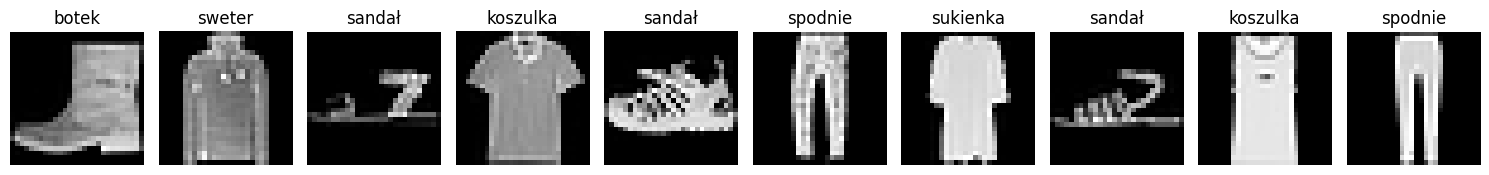

In [ ]:
# Twoje rozwiązanie
# 1. Wczytanie danych
train_full = datasets.FashionMNIST(root="data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.FashionMNIST(root="data", train=False, download=True, transform=transforms.ToTensor())

# 2. Podział na treningowy i walidacyjny
train_set, val_set = random_split(
    train_full,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

# 3. TrainLoader
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1000, shuffle=False)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False)

# 4. 10 pierwszych obrazów treningowych z nazwami
fig, axes = plt.subplots(1, 10, figsize=(15, 3))
for i in range(10):
    image, label = train_set[i]
    axes[i].imshow(image.squeeze(), cmap="gray")
    axes[i].set_title(klasy[label])
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# TEST
assert len(train_set) == 50_000 and len(val_set) == 10_000 and len(test_set) == 10_000
assert tuple(train_full[0][0].shape) == (1, 28, 28)
print("1 OK")

1 OK


---
## 2. Funkcje uczenia i oceny
Napisz (lub przenieś z wzoru i zrozum!) trzy funkcje:
- `epoka_uczenia(model, loader, optimizer)` – jedna epoka uczenia z `model.train()`,
- `ocen(model, loader)` – zwraca `(strata, accuracy)` z `model.eval()` i `torch.no_grad()`,
- `trenuj(model, epochs=5, lr=1e-3)` – optymalizator Adam; po każdej epoce zapisuje accuracy na train i val w słowniku z kluczami `"train acc"`, `"val acc"` i go zwraca.

In [ ]:
# Twoje rozwiązanie
def epoka_uczenia(model, loader, optimizer):
    model.train()
    for x, y in loader:
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()

def ocen(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for x, y in loader:
            outputs = model(x)
            loss = nn.functional.cross_entropy(outputs, y, reduction='sum')
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += y.size(0)
            correct += (predicted == y).sum().item()
    return total_loss / total, correct / total

def trenuj(model, epochs=5, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train acc": [], "val acc": []}
    for _ in range(epochs):
        epoka_uczenia(model, train_loader, optimizer)
        hist["train acc"].append(ocen(model, train_loader)[1])
        hist["val acc"].append(ocen(model, val_loader)[1])
    return hist

---
## 3. Model bazowy: regresja softmax
`torch.manual_seed(0)`, potem `model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))` i `hist_soft = trenuj(model_soft)`.

In [ ]:
# Twoje rozwiązanie
torch.manual_seed(0)
model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
hist_soft = trenuj(model_soft)

In [ ]:
# TEST
assert len(hist_soft["val acc"]) == 5
assert 0.78 < hist_soft["val acc"][-1] < 0.88
print("3 OK")

3 OK


---
## 4. Dwie sieci
Przed każdym modelem `torch.manual_seed(0)`:
- `model_maly`: `Flatten → Linear(784, 128) → ReLU → Linear(128, 10)` → `hist_maly`,
- `model_duzy`: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)` → `hist_duzy`.

Zbierz wyniki trzech modeli w `pd.DataFrame` o nazwie `wyniki` (indeks: `"softmax"`, `"sieć mała"`, `"sieć duża"`; kolumny: `"parametry"`, `"train acc"`, `"val acc"` – wartości po ostatniej epoce) i narysuj krzywe **val acc** wszystkich trzech modeli na jednym wykresie.

In [ ]:
# Twoje rozwiązanie

torch.manual_seed(0)
model_maly = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

torch.manual_seed(0)
model_duzy = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

hist_maly = trenuj(model_maly)
hist_duzy = trenuj(model_duzy)

wyniki = pd.DataFrame({
    "parametry": [
        sum(p.numel() for p in model_soft.parameters()),
        sum(p.numel() for p in model_maly.parameters()),
        sum(p.numel() for p in model_duzy.parameters())
    ],
    "train acc": [hist_soft["train acc"][-1], hist_maly["train acc"][-1], hist_duzy["train acc"][-1]],
    "val acc": [hist_soft["val acc"][-1], hist_maly["val acc"][-1], hist_duzy["val acc"][-1]]
}, index=["softmax", "sieć mała", "sieć duża"])



softmax:     7,850 parametrów, val acc 0.8458
sieć mała: 101,770 parametrów, val acc 0.8726
sieć duża: 235,146 parametrów, val acc 0.8762
softmax: train acc po 5 epokach = 0.8519
sieć mała: train acc po 5 epokach = 0.8848
sieć duża: train acc po 5 epokach = 0.8884


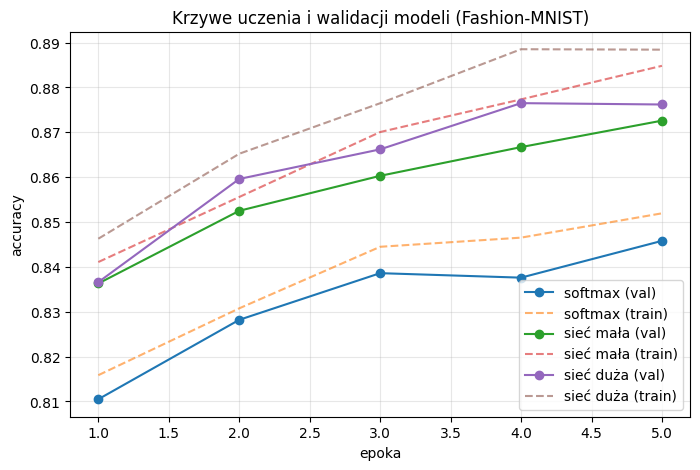

In [ ]:
#wykres
liczba_param = lambda m: sum(p.numel() for p in m.parameters())
print(f"softmax:   {liczba_param(model_soft):>7,} parametrów, val acc {hist_soft['val acc'][-1]:.4f}")
print(f"sieć mała: {liczba_param(model_maly):>7,} parametrów, val acc {hist_maly['val acc'][-1]:.4f}")
print(f"sieć duża: {liczba_param(model_duzy):>7,} parametrów, val acc {hist_duzy['val acc'][-1]:.4f}")

for model_name in wyniki.index:
    train_acc = wyniki.loc[model_name, 'train acc']
    print(f"{model_name}: train acc po 5 epokach = {train_acc:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
for nazwa, h in [("softmax", hist_soft), ("sieć mała", hist_maly), ("sieć duża", hist_duzy)]:
    ax.plot(range(1, 6), h["val acc"], "o-", label=f"{nazwa} (val)")
    ax.plot(range(1, 6), h["train acc"], "--", alpha=0.6, label=f"{nazwa} (train)")

ax.set_xlabel("epoka")
ax.set_ylabel("accuracy")
ax.legend()
ax.grid(alpha=0.3)
plt.title("Krzywe uczenia i walidacji modeli (Fashion-MNIST)")
plt.show()

In [ ]:
# TEST
assert list(wyniki.index) == ["softmax", "sieć mała", "sieć duża"]
assert wyniki.loc["sieć mała", "parametry"] == 101_770 and wyniki.loc["sieć duża", "parametry"] == 235_146
assert wyniki.loc["sieć mała", "val acc"] > wyniki.loc["softmax", "val acc"]
print("4 OK")

4 OK


*Twoja odpowiedź:*
1. Ile zyskuje sieć względem softmaksu na Fashion-MNIST, a ile zyskiwała na MNIST (wzór)? Skąd różnica?
2. Czy duża sieć jest wyraźnie lepsza od małej? Czy 2,3 razy więcej parametrów się opłaca?
3. Porównaj train acc i val acc dla każdego modelu. Gdzie różnica jest największa i co może oznaczać?

In [ ]:
# 1. Zysk sieci względem softmaksu:
# - Na Fashion-MNIST:
#   - sieć mała: val acc wzrosło z 0.8458 do 0.8726 -> zysk +2.68 p.p.
#   - sieć duża: val acc wzrosło z 0.8458 do 0.8762 -> zysk +3.04 p.p.
# - Na MNIST(wzór):
#   - sieć mała: val acc wzrosło z 0.9132 do 0.9623 -> zysk +4.91 p.p.

# - Różnica wynika z tego, że Fashion-MNIST jest trudniejszym zbiorem niż cyfry MNIST - wiele klas ubrań
#   (np. koszula, koszulka, sweter, płaszcz) ma bardzo podobne kontury na obrazku 28x28 i różni
#   się drobnymi detalami. Zwykła sieć gęsta po spłaszczeniu obrazu (nn.Flatten) traci informację
#   o położeniu i sąsiedztwie pikseli, więc sama nieliniowość daje mniejszy skok jakości niż przy
#   prostych kształtach cyfr w MNIST.
#
# 2. Czy duża sieć jest wyraźnie lepsza od małej i czy 2,3x więcej parametrów się opłaca?
# - Sieć duża (235 146 parametrów) uzyskała val acc = 0.8762, a sieć mała (101 770 parametrów)
#   uzyskała val acc = 0.8726. Różnica to zaledwie +0,36 p.p. (0.0036).
# - Zwiększenie liczby parametrów ok. 2,3 raza nie daje wyraźnej poprawy,
#   a czas i koszt obliczeń wyraźnie rosną. Wynik na walidacji poprawia się minimalnie.
#
# 3. Porównanie train acc i val acc (wartości train acc odczytane z wykresu po 5. epoce):
# - softmax:    train acc ~0.852 vs val acc 0.8458 (różnica ok. 0.6 p.p.)
# - sieć mała:  train acc ~0.885 vs val acc 0.8726 (różnica ok. 1.2 p.p.)
# - sieć duża:  train acc ~0.889 vs val acc 0.8762 (różnica ok. 1.3 p.p.)
# Największa różnica jest w sieci dużej. Wynika ona z tego, że sieć duża w 5 epoce nie poprawiła
# swojej wartości val. Może ona oznaczać, że model nauczył się już wszystkiego na podstawie swoich parametrów.

---
## 5. Ocena końcowa i błędy
1. `najlepszy` – nazwa modelu z najwyższym `val acc` w tabeli `wyniki`; `model_koncowy` – ten model.
2. `acc_test` – accuracy na zbiorze **testowym** (jedyny raz, kiedy go używasz).
3. Zbierz predykcje dla całego zbioru testowego (`y_true`, `y_pred` jako tablice NumPy) i narysuj macierz pomyłek z nazwami klas (`ConfusionMatrixDisplay.from_predictions`, `xticks_rotation=45`).
4. Wypisz 3 pary klas (prawdziwa → przewidziana), które model myli najczęściej.

Test accuracy najlepszego modelu (sieć duża): 0.8654


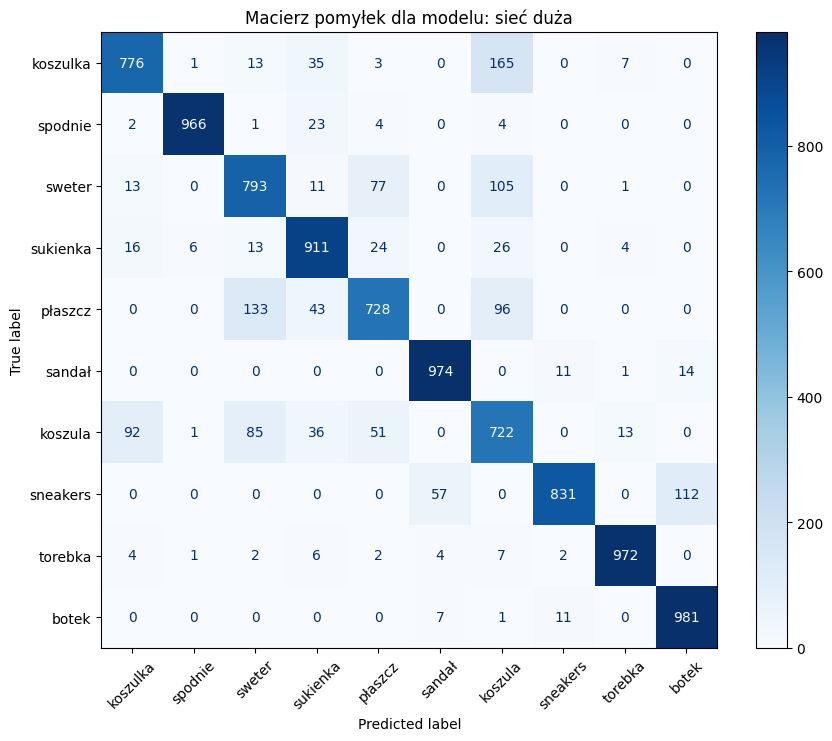


3 najczęstsze pomyłki modelu (prawdziwa -> przewidziana):
koszulka -> koszula: 165 razy
płaszcz -> sweter: 133 razy
sneakers -> botek: 112 razy


In [ ]:
# Twoje rozwiązanie
from sklearn.metrics import ConfusionMatrixDisplay

modele_map = {
    "softmax": model_soft,
    "sieć mała": model_maly,
    "sieć duża": model_duzy
}

najlepszy = wyniki["val acc"].idxmax()
model_koncowy = modele_map[najlepszy]

# 1. Obliczenie accuracy na zbiorze testowym
_, acc_test = ocen(model_koncowy, test_loader)
print(f"Test accuracy najlepszego modelu ({najlepszy}): {acc_test:.4f}")

# 2. Zbieranie predykcji
y_true_list = []
y_pred_list = []

model_koncowy.eval()
with torch.no_grad():
    for x, y in test_loader:
        outputs = model_koncowy(x)
        preds = outputs.argmax(dim=1)
        y_true_list.extend(y.numpy())
        y_pred_list.extend(preds.numpy())

y_true = np.array(y_true_list)
y_pred = np.array(y_pred_list)

# Macierz
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=klasy,
    xticks_rotation=45,
    ax=ax,
    cmap="Blues"
)
plt.title(f"Macierz pomyłek dla modelu: {najlepszy}")
plt.show()

# 4. Wypisanie 3 par klas, które model myli najczęściej
errors = {}
for true_idx, pred_idx in zip(y_true, y_pred):
    if true_idx != pred_idx:
        pair = (true_idx, pred_idx)
        errors[pair] = errors.get(pair, 0) + 1

# Sortowanie błędów od najczęstszych
najczestsze_bledy = sorted(errors.items(), key=lambda x: x[1], reverse=True)[:3]

print("\n3 najczęstsze pomyłki modelu (prawdziwa -> przewidziana):")
for (true_idx, pred_idx), count in najczestsze_bledy:
    print(f"{klasy[true_idx]} -> {klasy[pred_idx]}: {count} razy")



In [ ]:
from sklearn.metrics import classification_report

# Obliczenie dokładności dla każdej klasy osobno
class_accuracies = {}
for i, klasa in enumerate(klasy):
    maska_prawdziwa = (y_true == i)
    sukcesy = (y_pred[maska_prawdziwa] == i).sum()
    ogolem = maska_prawdziwa.sum()
    skutecznosc = sukcesy / ogolem if ogolem > 0 else 0
    class_accuracies[klasa] = skutecznosc

# Sortowanie klas według najlepszej skuteczności
najlepsze_klasy = sorted(class_accuracies.items(), key=lambda x: x[1], reverse=True)

print("Skuteczność klas (od najbardziej do najmniej poprawnej):")
for klasa, celnosc in najlepsze_klasy:
    print(f"{klasa}: {celnosc*100:.2f}%")

Skuteczność klas (od najbardziej do najmniej poprawnej):
botek: 98.10%
sandał: 97.40%
torebka: 97.20%
spodnie: 96.60%
sukienka: 91.10%
sneakers: 83.10%
sweter: 79.30%
koszulka: 77.60%
płaszcz: 72.80%
koszula: 72.20%


In [ ]:
# TEST
assert najlepszy == wyniki["val acc"].idxmax()
assert 0.82 < acc_test < 0.92
assert len(y_true) == len(y_pred) == 10_000
print("5 OK")

5 OK


*Twoja odpowiedź:* które klasy model myli najczęściej? Czy człowiek też miałby z nimi kłopot na obrazku 28 × 28? Która klasa jest najłatwiejsza i dlaczego?

In [ ]:
# Model myli najczęsciej:
# koszulę z koszulką
# sweter z koszulką
# płaszcz ze swetrem
# sweter z koszulą
# botek ze sneakersem
#
# Człowiek też miałby z nimi kłopot na obrazku 28x28. Wszystko dlatego, że obrazki są
# w zbyt małej rozdzielczości. Gdyby były 2 lub 3 razy większe prawdopodobne jest to, że
# takowy problem by zniknął, jednakże proces szkolenia modelu trwałby dużo dłużej.

# Najłatwiejsza jest klasa spodni (97.7%) oraz torebki (97.2%), ponieważ w całym zbiorze cechuje się tym, że nie posiada żadnych
# obiektów podobnych. W przeciwieństwie do np, ubioru górnej części ciała gdzie w zbiorze znajdują się zarówno
# koszule, koszulki, swetry, płaszcze i sukienki.

---
## 6. Dla chętnych
1. Naucz `model_duzy` od nowa przez **15 epok** i narysuj train acc i val acc. Od której epoki krzywe zaczynają się rozjeżdżać? (To przeuczenie – temat następnych zajęć.)
2. Zamień `ReLU` na `Sigmoid` w małej sieci. Jak zmienia się szybkość uczenia?
3. Narysuj 10 obrazów testowych, na których model się pomylił, z podpisem „przewidziane (prawdziwe)”.

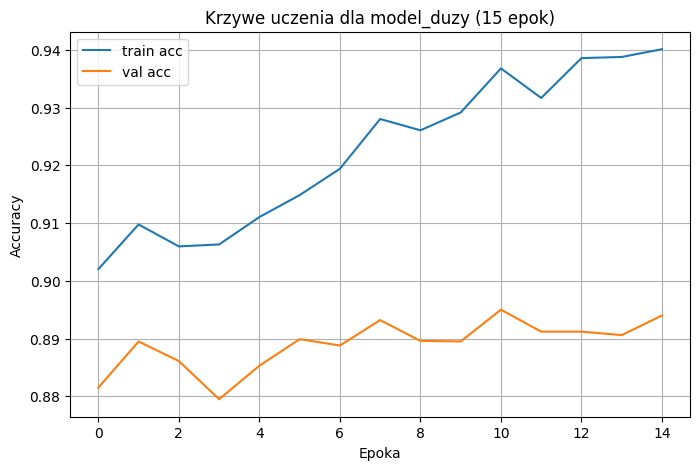

Mała sieć z ReLU (val acc po 5 epokach): 0.8726
Mała sieć z Sigmoid (val acc po 5 epokach): 0.8619


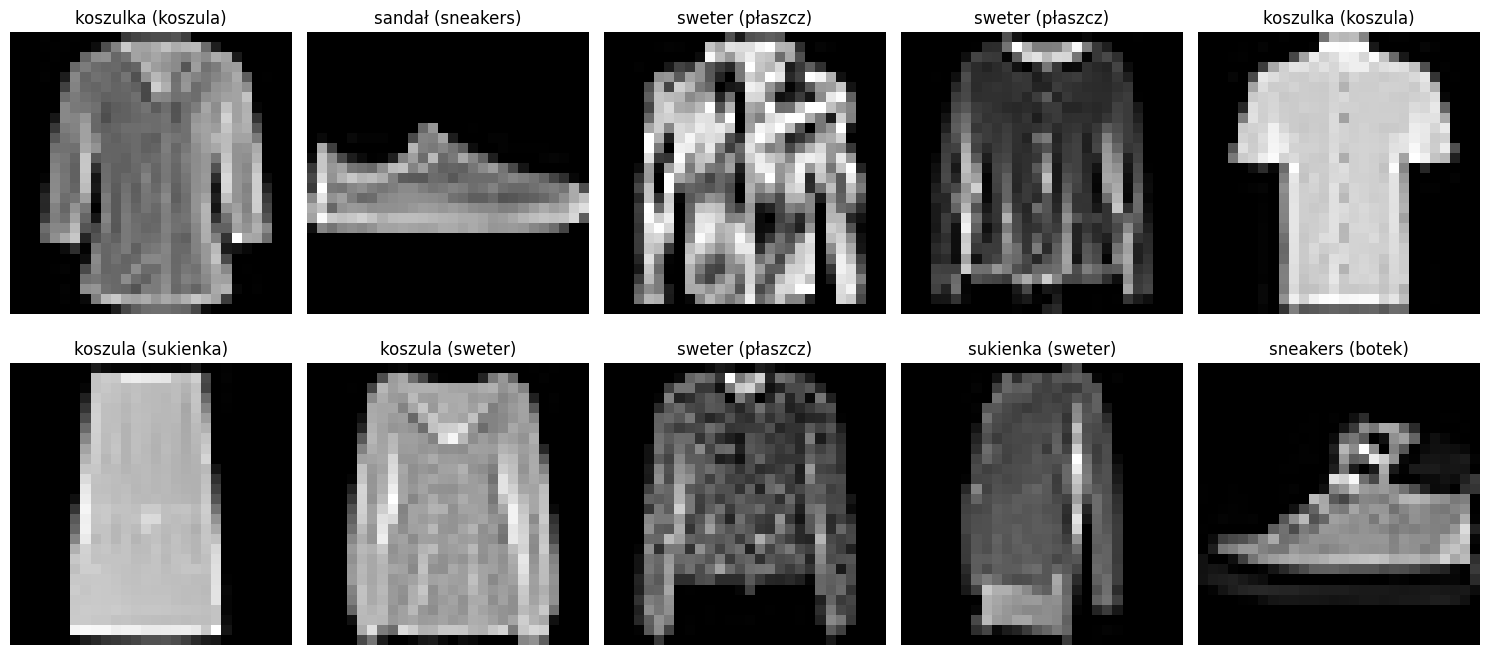

In [ ]:
# 1. Trening model_duzy od nowa przez 15 epok
torch.manual_seed(0)

hist_duzy_15 = trenuj(model_duzy, epochs=15)

plt.figure(figsize=(8, 5))
plt.plot(hist_duzy_15["train acc"], label="train acc")
plt.plot(hist_duzy_15["val acc"], label="val acc")
plt.xlabel("Epoka")
plt.ylabel("Accuracy")
plt.title("Krzywe uczenia dla model_duzy (15 epok)")
plt.legend()
plt.grid(True)
plt.show()

# 2. Zamiana ReLU na Sigmoid w małej sieci
torch.manual_seed(0)
model_maly_sigmoid = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10)
)
hist_maly_sigmoid = trenuj(model_maly_sigmoid, epochs=5)
print(f"Mała sieć z ReLU (val acc po 5 epokach): {hist_maly['val acc'][-1]:.4f}")
print(f"Mała sieć z Sigmoid (val acc po 5 epokach): {hist_maly_sigmoid['val acc'][-1]:.4f}")

# 3. Narysowanie 10 obrazów testowych, na których model_koncowy się pomylił
model_koncowy.eval()
bledne_obrazy = []

with torch.no_grad():
    for x, y in test_loader:
        outputs = model_koncowy(x)
        preds = outputs.argmax(dim=1)

        mask = preds != y
        if mask.any():
            for i in range(len(y)):
                if mask[i]:
                    bledne_obrazy.append((x[i], preds[i].item(), y[i].item()))
                    if len(bledne_obrazy) == 10:
                        break
        if len(bledne_obrazy) == 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for idx, (img, pred, true) in enumerate(bledne_obrazy):
    ax = axes[idx // 5, idx % 5]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"{klasy[pred]} ({klasy[true]})")
    ax.axis("off")
plt.tight_layout()
plt.show()